Jacobi temperatures: [71.66666665 63.33333331 54.99999997 46.66666664 38.33333332]
Gauss-Seidel temperatures: [71.66666665 63.3333333  54.99999997 46.66666665 38.33333332]
Direct solution: [71.66666667 63.33333333 55.         46.66666667 38.33333333]


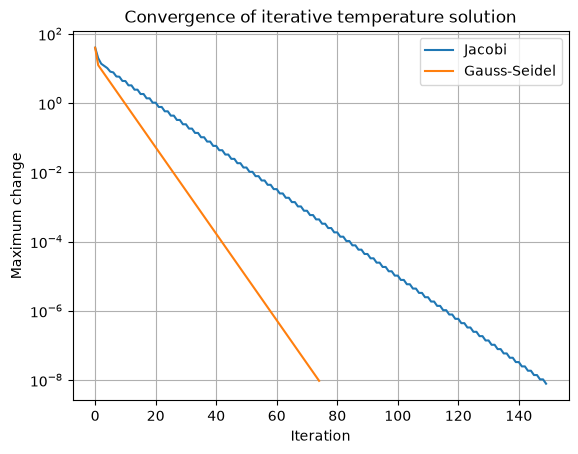

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#G. Iterative Methods for Linear Systems

# Simplified steady-state temperature model for five interior grid points.
# Diagonal dominance makes Jacobi and Gauss-Seidel converge.
A = np.array([
    [ 2., -1., 0., 0., 0.],
    [-1., 2., -1., 0., 0.],
    [ 0., -1., 2., -1., 0.],
    [ 0., 0., -1., 2., -1.],
    [ 0., 0., 0., -1., 2.]
])

# Boundary influence: left boundary = 80 C, right boundary = 30 C
b = np.array([80., 0., 0., 0., 30.])

def jacobi(A, b, tol=1e-8, max_iter=500):
    D = np.diag(A)
    R = A - np.diagflat(D)
    x = np.zeros_like(b)
    errors = []

    for _ in range(max_iter):
        x_new = (b - R @ x) / D
        error = np.linalg.norm(x_new - x, ord=np.inf)
        errors.append(error)
        if error < tol:
            return x_new, errors
        x = x_new

    return x, errors

def gauss_seidel(A, b, tol=1e-8, max_iter=500):
    x = np.zeros_like(b)
    errors = []

    for _ in range(max_iter):
        old = x.copy()
        for i in range(len(b)):
            x[i] = (
                b[i]
                - A[i, :i] @ x[:i]
                - A[i, i+1:] @ old[i+1:]
            ) / A[i, i]

        error = np.linalg.norm(x - old, ord=np.inf)
        errors.append(error)
        if error < tol:
            return x, errors

    return x, errors

x_j, err_j = jacobi(A, b)
x_gs, err_gs = gauss_seidel(A, b)
x_exact = np.linalg.solve(A, b)

print("Jacobi temperatures:", x_j)
print("Gauss-Seidel temperatures:", x_gs)
print("Direct solution:", x_exact)

plt.semilogy(err_j, label="Jacobi")
plt.semilogy(err_gs, label="Gauss-Seidel")
plt.xlabel("Iteration")
plt.ylabel("Maximum change")
plt.title("Convergence of iterative temperature solution")
plt.legend()
plt.grid(True)
plt.show()